# FiKCE-BTC BERT Experiments (Without Undersampling (Table 4))

Runs all 9 `BERT` configurations (`none`, `tfidf`, `tfidf_filter` x `CNN`, `LSTM`, `CNN-LSTM`) with train-only keyword extraction and early stopping on validation loss, and outputs **Table 2**, **Table 4**, **Table 6a/6b**, and **Fig. 2** confusion matrix comparison.

In [1]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import gc
import glob
import json
import copy
import random
import re
import shutil
import warnings
from collections import Counter

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 1000)

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)
from sklearn.utils import resample

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel


def set_seed(seed: int = 42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


SEED = 42
set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Using device: cuda
GPU: Tesla T4


# 1. Load Dataset & Text Preprocessing

In [2]:
def resolve_dataset_path() -> str:
    candidates = [
        "/kaggle/input/blooms-taxonomy-dataset/blooms_taxonomy_dataset.csv",
        "../../data/blooms_taxonomy_dataset.csv",
        "data/blooms_taxonomy_dataset.csv",
        "blooms_taxonomy_dataset.csv",
    ]
    for p in candidates:
        if os.path.isfile(p):
            return p
    kaggle_matches = sorted(glob.glob("/kaggle/input/**/blooms_taxonomy_dataset.csv", recursive=True))
    if kaggle_matches:
        return kaggle_matches[0]
    kaggle_any_csv = sorted(glob.glob("/kaggle/input/**/*.csv", recursive=True))
    if len(kaggle_any_csv) == 1:
        return kaggle_any_csv[0]
    raise FileNotFoundError(
        "Could not locate blooms_taxonomy_dataset.csv in /kaggle/input or local data/ directory."
    )


def preprocess_text(text: str) -> str:
    if pd.isna(text):
        return ""
    text = str(text).lower()
    text = re.sub(
        r"http[s]?://(?:[a-zA-Z]|[0-9]|[$-_@.&+]|[!*\\(\\),]|(?:%[0-9a-fA-F][0-9a-fA-F]))+",
        "",
        text,
    )
    text = re.sub(
        r"www\.(?:[a-zA-Z]|[0-9]|[$-_@.&+]|[!*\\(\\),]|(?:%[0-9a-fA-F][0-9a-fA-F]))+",
        "",
        text,
    )
    text = re.sub(r"[^a-zA-Z0-9\s\.\,\?\!\-]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


dataset_path = resolve_dataset_path()
df = pd.read_csv(dataset_path)
assert {"Questions", "Category"}.issubset(set(df.columns)), f"Unexpected columns: {list(df.columns)}"
df = df.dropna(subset=["Questions", "Category"]).reset_index(drop=True)
df["Questions_clean"] = df["Questions"].apply(preprocess_text)

print(f"Loaded dataset from: {dataset_path}")
print(f"Shape: {df.shape}")
print("\nInitial Category Distribution (Table 1):")
label_counts = df["Category"].value_counts().sort_index()
print(label_counts)

Loaded dataset from: /kaggle/input/datasets/imamfatih/blooms-taxonomy-dataset/blooms_taxonomy_dataset.csv
Shape: (8767, 3)

Initial Category Distribution (Table 1):
Category
BT1    2582
BT2    1801
BT3    1508
BT4    1293
BT5     783
BT6     800
Name: count, dtype: int64


# 2. Stratified Train / Validation / Test Split


Split sizes -> Train: 6311, Val: 702, Test: 1754


,Original,Train (pre-US),Train (used),Validation,Test
Category,,,,,
BT1,2582,1859,1859,207,516
BT2,1801,1297,1297,144,360
BT3,1508,1085,1085,121,302
BT4,1293,931,931,103,259
BT5,783,563,563,63,157
BT6,800,576,576,64,160
Total,8767,6311,6311,702,1754


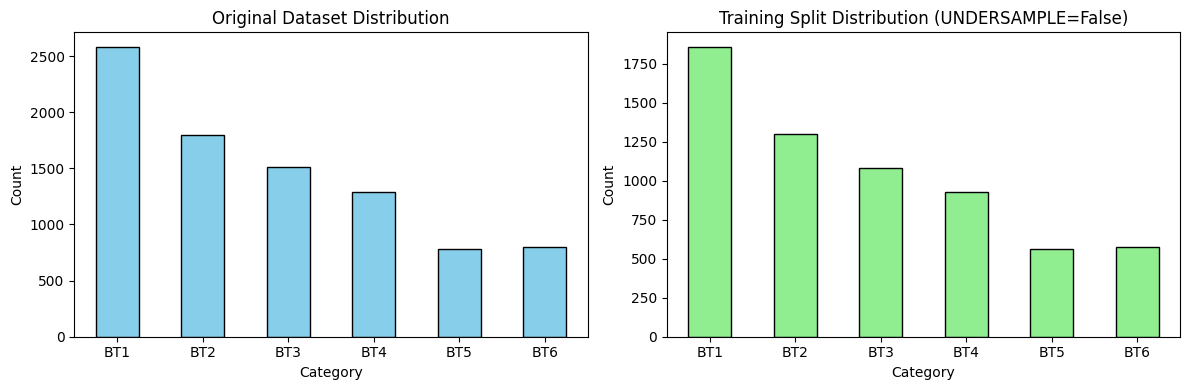

In [3]:
UNDERSAMPLE = False  # Table 4 (without undersampling)

# 1) Stratified 80/20 split: test_df is held out and never touched until final evaluation
trainval_df, test_df = train_test_split(
    df, test_size=0.2, random_state=SEED, stratify=df["Category"]
)

# 2) Stratified 10% validation split from trainval_df for early stopping & best checkpoint selection
train_df_raw, val_df = train_test_split(
    trainval_df, test_size=0.1, random_state=SEED, stratify=trainval_df["Category"]
)

# Verify zero index overlap across splits before resetting indices
assert len(set(train_df_raw.index) & set(val_df.index)) == 0
assert len(set(train_df_raw.index) & set(test_df.index)) == 0
assert len(set(val_df.index) & set(test_df.index)) == 0

# 3) Apply random undersampling ONLY to train_df (val_df and test_df keep original distribution)
if UNDERSAMPLE:
    n_min = int(train_df_raw["Category"].value_counts().min())
    resampled_parts: list[pd.DataFrame] = [
        pd.DataFrame(resample(g, replace=False, n_samples=n_min, random_state=SEED))
        for _, g in train_df_raw.groupby("Category", sort=True)
    ]
    train_df = (
        pd.concat(resampled_parts, ignore_index=True)
        .sample(frac=1, random_state=SEED)
        .reset_index(drop=True)
    )
    print(f"Undersampling applied to TRAIN ONLY -> n_min={n_min}, train={len(train_df)}")
else:
    train_df = train_df_raw.reset_index(drop=True)

val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
classes = sorted(train_df["Category"].astype(str).unique().tolist())

split_summary = pd.DataFrame({
    "Original": df["Category"].value_counts().sort_index(),
    "Train (pre-US)": train_df_raw["Category"].value_counts().sort_index(),
    "Train (used)": train_df["Category"].value_counts().sort_index(),
    "Validation": val_df["Category"].value_counts().sort_index(),
    "Test": test_df["Category"].value_counts().sort_index(),
})
split_summary.loc["Total"] = split_summary.sum()
print(f"\nSplit sizes -> Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")
display(split_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["Category"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="skyblue", edgecolor="black")
axes[0].set_title("Original Dataset Distribution")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=0)

train_df["Category"].value_counts().sort_index().plot(kind="bar", ax=axes[1], color="lightgreen", edgecolor="black")
axes[1].set_title(f"Training Split Distribution (UNDERSAMPLE={UNDERSAMPLE})")
axes[1].set_xlabel("Category")
axes[1].set_ylabel("Count")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

# 3. Train-Only Filtered Keyword Extraction (Table 2)

In [4]:
def build_filtered_vocab(train_texts, train_labels, classes, top_n=50, tau=1.5, eps=1e-5):
    y = np.asarray(train_labels)
    cv = CountVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2)
    Xc = cv.fit_transform(train_texts)
    vocab = cv.get_feature_names_out()

    tf = np.vstack([np.asarray(Xc[y == c].sum(0)).ravel() for c in classes])
    n_classes = len(classes)
    df_cat = (tf > 0).sum(0)
    tfidf = tf * np.log(n_classes / np.maximum(df_cat, 1))
    total = tf.sum(0)

    per_class = {}
    for k, category in enumerate(classes):
        candidates = np.argsort(-tfidf[k])[:top_n]
        keep = []
        for j in candidates:
            ratio = tf[k, j] / ((total[j] - tf[k, j]) + eps)
            if ratio >= tau:
                keep.append(j)
        per_class[category] = keep

    counts = Counter(j for values in per_class.values() for j in values)
    keywords = sorted({vocab[j] for values in per_class.values() for j in values if counts[j] == 1})
    kept_by_class = {
        category: [vocab[j] for j in values if counts[j] == 1]
        for category, values in per_class.items()
    }
    return keywords, kept_by_class


def prepare_keyword_features(train_df, val_df, test_df, keyword_mode, filtered_vocab=None):
    if keyword_mode == "tfidf_filter":
        assert filtered_vocab is not None and len(filtered_vocab) > 0, "Filtered vocabulary K is empty"
        # Use stop_words="english" to match CountVectorizer tokenization for bigrams in K
        kw_vec = TfidfVectorizer(vocabulary=filtered_vocab, stop_words="english", ngram_range=(1, 2))
        X_kw_train = kw_vec.fit_transform(train_df["Questions_clean"]).toarray().astype(np.float32)
        X_kw_val = kw_vec.transform(val_df["Questions_clean"]).toarray().astype(np.float32)
        X_kw_test = kw_vec.transform(test_df["Questions_clean"]).toarray().astype(np.float32)
    elif keyword_mode == "tfidf":
        kw_vec = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), max_features=90)
        X_kw_train = kw_vec.fit_transform(train_df["Questions_clean"]).toarray().astype(np.float32)
        X_kw_val = kw_vec.transform(val_df["Questions_clean"]).toarray().astype(np.float32)
        X_kw_test = kw_vec.transform(test_df["Questions_clean"]).toarray().astype(np.float32)
    elif keyword_mode == "none":
        X_kw_train = np.zeros((len(train_df), 1), dtype=np.float32)
        X_kw_val = np.zeros((len(val_df), 1), dtype=np.float32)
        X_kw_test = np.zeros((len(test_df), 1), dtype=np.float32)
    else:
        raise ValueError(f"Unknown keyword_mode: {keyword_mode}")
    return X_kw_train, X_kw_val, X_kw_test


# Fit filtered keyword vocabulary strictly on train_df
K, kw_by_class = build_filtered_vocab(
    train_df["Questions_clean"], train_df["Category"], classes, top_n=50, tau=1.5, eps=1e-5
)

table2_rows = []
for c in classes:
    kws = kw_by_class[c]
    table2_rows.append({
        "Class": c,
        "Filtered_Count": len(kws),
        "Top_10_Unique_Keywords": ", ".join(kws[:10]),
        "All_Unique_Keywords": ", ".join(kws),
    })

table2_df = pd.DataFrame(table2_rows)
print(f"Total unique filtered keywords (p): {len(K)} (UNDERSAMPLE={UNDERSAMPLE})")
print("\nTable 2. Filtered Keyword Distribution Each Class (Top 10):")
display(table2_df[["Class", "Filtered_Count", "Top_10_Unique_Keywords"]])

os.makedirs("outputs", exist_ok=True)
table2_df.to_csv(f"outputs/table2_keywords_undersample{UNDERSAMPLE}.csv", index=False)
with open(f"outputs/table2_keywords_undersample{UNDERSAMPLE}.json", "w") as f:
    json.dump({"p": len(K), "by_class": kw_by_class}, f, indent=2)

Total unique filtered keywords (p): 270 (UNDERSAMPLE=False)

Table 2. Filtered Keyword Distribution Each Class (Top 10):


,Class,Filtered_Count,Top_10_Unique_Keywords
0,BT1,41,"define, recall, recite, write note, quote, recognize, tabulate, purpose, favorite, output given"
1,BT2,40,"discussing, discuss principles, interpret, interpret concept, briefly explain, youre, explaining, compare various, paraphrase, suppose youre"
2,BT3,47,"involving, apply, problem involving, mm, apply principles, demonstrate, kn, 200, fig, calculate"
3,BT4,46,"break, distinguish, differentiate, contrast, break complex, versus, information complex, contrast principles, compare features, impact different"
4,BT5,47,"judge, debate ethical, debate, criticize, critique, considerations using, ethical implications, recommend, assess value, justify"
5,BT6,49,"invent, devise, automatically, formulate, invent method, invent new, combined create, formulate algorithm, conclusions draw, draw combining"


# 4. Dataset, Model Architecture & Training Utilities

In [5]:
KEYWORD_LABEL_MAP = {
    "none": "None",
    "tfidf": "TF-IDF",
    "tfidf_filter": "TF-IDF + Filtered Keyword",
}

EMBEDDING_LABEL_MAP = {
    "bert-base-uncased": "BERT",
    "roberta-base": "RoBERTa",
}

VARIANT_LABEL_MAP = {
    "cnn": "CNN",
    "lstm": "LSTM",
    "cnn_lstm": "CNN-LSTM",
}

SAVE_MODEL_WEIGHTS = True  # Saves one .pth checkpoint per run inside outputs/


class BloomDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, label_encoder, keywords=None, max_length=128):
        encodings = tokenizer(
            list(map(str, texts)),
            truncation=True,
            padding="max_length",
            max_length=max_length,
            return_tensors="pt",
        )
        self.input_ids = encodings["input_ids"]
        self.attention_mask = encodings["attention_mask"]
        self.labels = torch.tensor(np.asarray(label_encoder.transform(labels), dtype=np.int64), dtype=torch.long)
        self.keywords = torch.tensor(keywords, dtype=torch.float32) if keywords is not None else None

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {
            "input_ids": self.input_ids[idx],
            "attention_mask": self.attention_mask[idx],
            "label": self.labels[idx],
        }
        if self.keywords is not None:
            item["keywords"] = self.keywords[idx]
        return item


class BloomClassifier(nn.Module):
    def __init__(
        self,
        backbone,
        num_classes,
        hidden_dim=256,
        variant="cnn_lstm",
        keyword_feature=False,
        num_keywords=0,
        unfreeze_layers=2,
    ):
        super().__init__()
        assert variant in ["cnn", "lstm", "cnn_lstm"], "Invalid model variant"
        self.variant = variant
        self.keyword_feature = keyword_feature
        self.bert = backbone
        self.bert_dim = getattr(backbone.config, "hidden_size", 768)
        self.unfreeze_bert_layers(unfreeze_layers)

        if variant in ["cnn", "cnn_lstm"]:
            self.conv1 = nn.Conv1d(self.bert_dim, 128, kernel_size=3, padding=1)
            self.conv2 = nn.Conv1d(128, 64, kernel_size=3, padding=1)
            self.pool = nn.AdaptiveMaxPool1d(1)
        if variant in ["lstm", "cnn_lstm"]:
            self.lstm = nn.LSTM(
                self.bert_dim, hidden_dim // 2, batch_first=True, bidirectional=True
            )
        if self.keyword_feature:
            assert num_keywords > 0, "num_keywords must be > 0 when keyword_feature=True"
            self.keyword_fc = nn.Linear(num_keywords, 64)

        combined_dim = 64 if variant in ["cnn", "cnn_lstm"] else 0
        combined_dim += hidden_dim if variant in ["lstm", "cnn_lstm"] else 0
        combined_dim += 64 if self.keyword_feature else 0

        self.classifier = nn.Sequential(
            nn.Linear(combined_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden_dim // 2, num_classes),
        )

    def unfreeze_bert_layers(self, num_layers=2):
        for param in self.bert.parameters():
            param.requires_grad = False
        total_layers = len(self.bert.encoder.layer)
        for layer in self.bert.encoder.layer[total_layers - num_layers :]:
            for param in layer.parameters():
                param.requires_grad = True
        if getattr(self.bert, "pooler", None) is not None:
            for param in self.bert.pooler.parameters():
                param.requires_grad = True

    def get_parameter_groups(self):
        bert_params = [p for n, p in self.named_parameters() if p.requires_grad and n.startswith("bert.")]
        other_params = [p for n, p in self.named_parameters() if p.requires_grad and not n.startswith("bert.")]
        return [
            {"params": bert_params, "lr": 1e-5, "name": "bert"},
            {"params": other_params, "lr": 2e-4, "name": "classifier"},
        ]

    def forward(self, input_ids, attention_mask, keywords=None):
        sequence_output = self.bert(
            input_ids=input_ids, attention_mask=attention_mask
        ).last_hidden_state
        features = []
        if self.variant in ["cnn", "cnn_lstm"]:
            cnn_input = sequence_output.permute(0, 2, 1)
            cnn_out = F.relu(self.conv1(cnn_input))
            cnn_out = F.relu(self.conv2(cnn_out))
            features.append(self.pool(cnn_out).squeeze(-1))
        if self.variant in ["lstm", "cnn_lstm"]:
            _, (hidden, _) = self.lstm(sequence_output)
            features.append(hidden.permute(1, 0, 2).contiguous().view(hidden.size(1), -1))
        if self.keyword_feature:
            features.append(F.relu(self.keyword_fc(keywords)))
        combined = torch.cat(features, dim=1)
        combined = combined / (combined.norm(p=2, dim=1, keepdim=True) + 1e-7)
        return self.classifier(combined)


class FocalLoss(nn.Module):
    def __init__(self, alpha=1.0, gamma=2.0, reduction="mean"):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        targets = targets.view(-1)
        logpt = F.log_softmax(inputs, dim=1)
        pt = torch.exp(logpt)
        logpt = logpt.gather(1, targets.unsqueeze(1)).squeeze(1)
        pt = pt.gather(1, targets.unsqueeze(1)).squeeze(1)
        loss = -self.alpha * (1 - pt) ** self.gamma * logpt
        return loss.mean() if self.reduction == "mean" else loss.sum()


def compute_confusion_stats(cm, labels):
    adj = {
        f"{labels[i]}<->{labels[i + 1]}": int(cm[i, i + 1] + cm[i + 1, i])
        for i in range(len(labels) - 1)
    }
    total_errors = int(cm.sum() - np.trace(cm))
    adj_errors = int(sum(adj.values()))
    non_adj_errors = int(total_errors - adj_errors)
    non_adj_pairs = {}
    for i in range(len(labels)):
        for j in range(len(labels)):
            if abs(i - j) > 1 and cm[i, j] > 0:
                non_adj_pairs[f"{labels[i]}->{labels[j]}"] = int(cm[i, j])
    return adj, adj_errors, non_adj_errors, total_errors, non_adj_pairs


def run_single_experiment(
    embedding_name: str,
    variant: str,
    keyword_mode: str,
    train_df: pd.DataFrame,
    val_df: pd.DataFrame,
    test_df: pd.DataFrame,
    classes: list,
    X_kw_train=None,
    X_kw_val=None,
    X_kw_test=None,
    epochs: int = 50,
    patience: int = 5,
    batch_size: int = 16,
    seed: int = 42,
):
    print("\n" + "=" * 80)
    print(
        f"RUN: Embedding={EMBEDDING_LABEL_MAP.get(embedding_name, embedding_name)} ({embedding_name}) | "
        f"Keywords={KEYWORD_LABEL_MAP.get(keyword_mode, keyword_mode)} ({keyword_mode}) | "
        f"Model={VARIANT_LABEL_MAP.get(variant, variant)} ({variant}) | UNDERSAMPLE={UNDERSAMPLE}"
    )
    print("=" * 80)

    set_seed(seed)

    X_text_train = train_df["Questions_clean"].to_numpy()
    X_text_val = val_df["Questions_clean"].to_numpy()
    X_text_test = test_df["Questions_clean"].to_numpy()
    y_train = train_df["Category"].to_numpy()
    y_val = val_df["Category"].to_numpy()
    y_test = test_df["Category"].to_numpy()

    label_encoder = LabelEncoder()
    label_encoder.fit(y_train)
    num_classes = len(label_encoder.classes_)

    tokenizer = AutoTokenizer.from_pretrained(embedding_name)
    backbone = AutoModel.from_pretrained(embedding_name).to(device)

    use_kw = keyword_mode != "none"
    train_dataset = BloomDataset(
        X_text_train, y_train, tokenizer, label_encoder,
        keywords=X_kw_train if use_kw else None, max_length=128
    )
    val_dataset = BloomDataset(
        X_text_val, y_val, tokenizer, label_encoder,
        keywords=X_kw_val if use_kw else None, max_length=128
    )
    test_dataset = BloomDataset(
        X_text_test, y_test, tokenizer, label_encoder,
        keywords=X_kw_test if use_kw else None, max_length=128
    )

    loader_gen = torch.Generator()
    loader_gen.manual_seed(seed)
    pin_mem = torch.cuda.is_available()

    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True, generator=loader_gen, pin_memory=pin_mem
    )
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, pin_memory=pin_mem)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, pin_memory=pin_mem)

    num_keywords = X_kw_train.shape[1] if (use_kw and X_kw_train is not None) else 0
    model = BloomClassifier(
        backbone=backbone,
        num_classes=num_classes,
        hidden_dim=256,
        variant=variant,
        keyword_feature=use_kw,
        num_keywords=num_keywords,
        unfreeze_layers=2,
    ).to(device)

    print(
        f"Trainable params: {sum(p.numel() for p in model.parameters() if p.requires_grad):,} / "
        f"{sum(p.numel() for p in model.parameters()):,} | num_keywords={num_keywords}"
    )

    criterion = FocalLoss(alpha=1.0, gamma=2.0)
    optimizer = optim.AdamW(model.get_parameter_groups(), weight_decay=0.01)
    scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(
        optimizer, T_0=10, T_mult=2, eta_min=1e-7
    )

    best_val_loss = float("inf")
    best_epoch = 0
    patience_counter = 0
    best_model_state = None
    train_losses, val_losses = [], []
    train_accuracies, val_accuracies = [], []

    for epoch in range(epochs):
        model.train()
        train_loss, train_correct, train_total = 0.0, 0, 0
        for batch in train_loader:
            input_ids = batch["input_ids"].to(device, non_blocking=True)
            attention_mask = batch["attention_mask"].to(device, non_blocking=True)
            labels = batch["label"].view(-1).to(device, non_blocking=True)
            keywords = batch["keywords"].to(device, non_blocking=True) if use_kw else None

            optimizer.zero_grad()
            outputs = model(input_ids, attention_mask, keywords)
            loss = criterion(outputs, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            train_loss += loss.item()
            train_correct += (outputs.argmax(dim=1) == labels).sum().item()
            train_total += labels.size(0)

        avg_train_loss = train_loss / len(train_loader)
        train_acc = 100.0 * train_correct / train_total

        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for batch in val_loader:
                input_ids = batch["input_ids"].to(device, non_blocking=True)
                attention_mask = batch["attention_mask"].to(device, non_blocking=True)
                labels = batch["label"].view(-1).to(device, non_blocking=True)
                keywords = batch["keywords"].to(device, non_blocking=True) if use_kw else None

                outputs = model(input_ids, attention_mask, keywords)
                loss = criterion(outputs, labels)
                val_loss += loss.item()
                val_correct += (outputs.argmax(dim=1) == labels).sum().item()
                val_total += labels.size(0)

        avg_val_loss = val_loss / len(val_loader)
        val_acc = 100.0 * val_correct / val_total
        scheduler.step()

        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)
        train_accuracies.append(train_acc)
        val_accuracies.append(val_acc)

        print(
            f"Epoch [{epoch + 1:02d}/{epochs}] "
            f"Train Loss: {avg_train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
            f"Val Loss: {avg_val_loss:.4f}, Val Acc: {val_acc:.2f}%"
        )

        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            best_epoch = epoch + 1
            best_model_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping triggered at epoch {epoch + 1} (best epoch: {best_epoch})")
                break

    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    # Final Test Evaluation
    model.eval()
    all_predictions, all_labels = [], []
    with torch.no_grad():
        for batch in test_loader:
            input_ids = batch["input_ids"].to(device, non_blocking=True)
            attention_mask = batch["attention_mask"].to(device, non_blocking=True)
            targets = batch["label"].view(-1).to(device, non_blocking=True)
            keywords = batch["keywords"].to(device, non_blocking=True) if use_kw else None

            outputs = model(input_ids, attention_mask, keywords)
            all_predictions.extend(outputs.argmax(dim=1).cpu().numpy())
            all_labels.extend(targets.cpu().numpy())

    pred_labels = label_encoder.inverse_transform(all_predictions)
    true_labels = label_encoder.inverse_transform(all_labels)

    acc = float(np.asarray(accuracy_score(true_labels, pred_labels)).item())
    p_raw, r_raw, f1_raw, _ = precision_recall_fscore_support(
        true_labels, pred_labels, average="weighted", zero_division=0
    )
    p_w = float(np.asarray(p_raw).item())
    r_w = float(np.asarray(r_raw).item())
    f1_w = float(np.asarray(f1_raw).item())
    f1_macro = float(np.asarray(f1_score(true_labels, pred_labels, average="macro", zero_division=0)).item())
    rep: dict = classification_report(  # type: ignore[assignment]
        true_labels, pred_labels, labels=classes, output_dict=True, zero_division=0
    )
    cm = confusion_matrix(true_labels, pred_labels, labels=classes)
    adj, adj_errors, non_adj_errors, total_errors, non_adj_pairs = compute_confusion_stats(cm, classes)

    print(
        f"\nTest Results -> Accuracy: {acc:.4f} | Precision (w): {p_w:.4f} | "
        f"Recall (w): {r_w:.4f} | F1 (w): {f1_w:.4f} | F1 (macro): {f1_macro:.4f}"
    )
    print(
        f"Misclassified: {total_errors}/{len(true_labels)} | "
        f"Adjacent errors: {adj_errors} ({(adj_errors / total_errors * 100) if total_errors else 0:.1f}%) | "
        f"Non-adjacent errors: {non_adj_errors}"
    )
    print("Adjacent confusions:", adj)
    print("\nClassification Report:")
    print(classification_report(true_labels, pred_labels, labels=classes, digits=4, zero_division=0))

    # Save artifacts & plots
    run_id = f"{embedding_name}_{variant}_{keyword_mode}_undersample{UNDERSAMPLE}"
    os.makedirs("outputs", exist_ok=True)
    run_dir = os.path.join("outputs", run_id)
    os.makedirs(run_dir, exist_ok=True)

    result_json = {
        "embedding_name": embedding_name,
        "variant": variant,
        "keyword_mode": keyword_mode,
        "undersample": UNDERSAMPLE,
        "best_epoch": best_epoch,
        "total_epochs_run": len(train_losses),
        "best_val_loss": float(best_val_loss),
        "accuracy": float(acc),
        "precision_w": float(p_w),
        "recall_w": float(r_w),
        "f1_weighted": float(f1_w),
        "f1_macro": float(f1_macro),
        "per_class": rep,
        "cm": cm.tolist(),
        "adjacent_confusions": adj,
        "adjacent_errors": adj_errors,
        "non_adjacent_errors": non_adj_errors,
        "total_misclassified": total_errors,
        "non_adjacent_pairs": non_adj_pairs,
    }
    json_filename = f"results_{run_id}.json"
    with open(json_filename, "w") as f:
        json.dump(result_json, f, indent=2)
    with open(os.path.join(run_dir, json_filename), "w") as f:
        json.dump(result_json, f, indent=2)

    # Complete 1x3 figure in a single cell
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
    fig.suptitle(
        f"{EMBEDDING_LABEL_MAP.get(embedding_name, embedding_name)} | "
        f"{KEYWORD_LABEL_MAP.get(keyword_mode, keyword_mode)} | "
        f"{VARIANT_LABEL_MAP.get(variant, variant)} (UNDERSAMPLE={UNDERSAMPLE})",
        fontsize=12,
        fontweight="bold",
    )

    axes[0].plot(range(1, len(train_losses) + 1), train_losses, label="Train Loss", marker="o", markersize=4)
    axes[0].plot(range(1, len(val_losses) + 1), val_losses, label="Val Loss", marker="s", markersize=4)
    axes[0].axvline(best_epoch, color="gray", linestyle="--", alpha=0.7, label=f"Best Epoch ({best_epoch})")
    axes[0].set_title("Training & Validation Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(range(1, len(train_accuracies) + 1), train_accuracies, label="Train Acc", marker="o", markersize=4)
    axes[1].plot(range(1, len(val_accuracies) + 1), val_accuracies, label="Val Acc", marker="s", markersize=4)
    axes[1].set_title("Training & Validation Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy (%)")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=axes[2]
    )
    axes[2].set_title("Test Confusion Matrix")
    axes[2].set_xlabel("Predicted")
    axes[2].set_ylabel("Actual")

    plt.tight_layout()
    plt.savefig(os.path.join(run_dir, f"training_and_cm_{run_id}.png"), dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    # Save standalone confusion matrix, reports, predictions, misclassified CSV
    fig_cm, ax_cm = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax_cm)
    ax_cm.set_title(f"Confusion Matrix: {EMBEDDING_LABEL_MAP.get(embedding_name, embedding_name)}-{VARIANT_LABEL_MAP.get(variant, variant)} ({keyword_mode})")
    ax_cm.set_xlabel("Predicted")
    ax_cm.set_ylabel("Actual")
    plt.tight_layout()
    plt.savefig(os.path.join(run_dir, f"confusion_matrix_{run_id}.png"), dpi=200, bbox_inches="tight")
    plt.close(fig_cm)

    with open(os.path.join(run_dir, f"classification_report_{run_id}.txt"), "w") as f:
        f.write(classification_report(true_labels, pred_labels, labels=classes, digits=4, zero_division=0))

    eval_results_df = pd.DataFrame({
        "Questions": test_df["Questions"].to_numpy(),
        "Questions_clean": X_text_test,
        "Actual": true_labels,
        "Predict": pred_labels,
    })
    eval_results_df.to_csv(os.path.join(run_dir, f"predictions_{run_id}.csv"), index=False)
    misclassified_df = eval_results_df[eval_results_df["Actual"] != eval_results_df["Predict"]]
    misclassified_df.to_csv(os.path.join(run_dir, f"misclassified_{run_id}.csv"), index=False)

    if SAVE_MODEL_WEIGHTS:
        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "label_classes": label_encoder.classes_.tolist(),
                "label_encoder": label_encoder,
                "model_config": {
                    "embedding_name": embedding_name,
                    "variant": variant,
                    "keyword_mode": keyword_mode,
                    "undersample": UNDERSAMPLE,
                    "num_classes": num_classes,
                    "num_keywords": num_keywords,
                    "hidden_dim": 256,
                },
            },
            os.path.join(run_dir, f"model_{run_id}.pth"),
        )

    # Free GPU memory cleanly before next run
    del model, backbone, optimizer, scheduler, train_loader, val_loader, test_loader
    del train_dataset, val_dataset, test_dataset
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return {
        "result": result_json,
        "cm": cm,
        "per_class": rep,
        "adj": adj,
        "true_labels": true_labels,
        "pred_labels": pred_labels,
    }

# 5. Run All 9 BERT Configurations (none / tfidf / tfidf_filter x CNN / LSTM / CNN-LSTM)


>>> Prepared keyword features for mode='none': train=(6311, 1), val=(702, 1), test=(1754, 1)

RUN: Embedding=BERT (bert-base-uncased) | Keywords=None (none) | Model=CNN (cnn) | UNDERSAMPLE=False


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Trainable params: 15,136,326 / 109,852,230 | num_keywords=0
Epoch [01/50] Train Loss: 0.9070, Train Acc: 42.40% | Val Loss: 0.5598, Val Acc: 63.96%
Epoch [02/50] Train Loss: 0.5068, Train Acc: 66.42% | Val Loss: 0.4105, Val Acc: 73.79%
Epoch [03/50] Train Loss: 0.3766, Train Acc: 74.69% | Val Loss: 0.3223, Val Acc: 77.35%
Epoch [04/50] Train Loss: 0.3059, Train Acc: 78.96% | Val Loss: 0.2947, Val Acc: 79.63%
Epoch [05/50] Train Loss: 0.2603, Train Acc: 81.76% | Val Loss: 0.2938, Val Acc: 78.92%
Epoch [06/50] Train Loss: 0.2211, Train Acc: 84.01% | Val Loss: 0.3053, Val Acc: 78.63%
Epoch [07/50] Train Loss: 0.1945, Train Acc: 86.04% | Val Loss: 0.3019, Val Acc: 80.20%
Epoch [08/50] Train Loss: 0.1692, Train Acc: 87.18% | Val Loss: 0.3056, Val Acc: 80.20%
Epoch [09/50] Train Loss: 0.1569, Train Acc: 88.15% | Val Loss: 0.3100, Val Acc: 79.91%
Epoch [10/50] Train Loss: 0.1504, Train Acc: 88.84% | Val Loss: 0.3092, Val Acc: 79.77%
Early stopping triggered at epoch 10 (best epoch: 5)

Test R

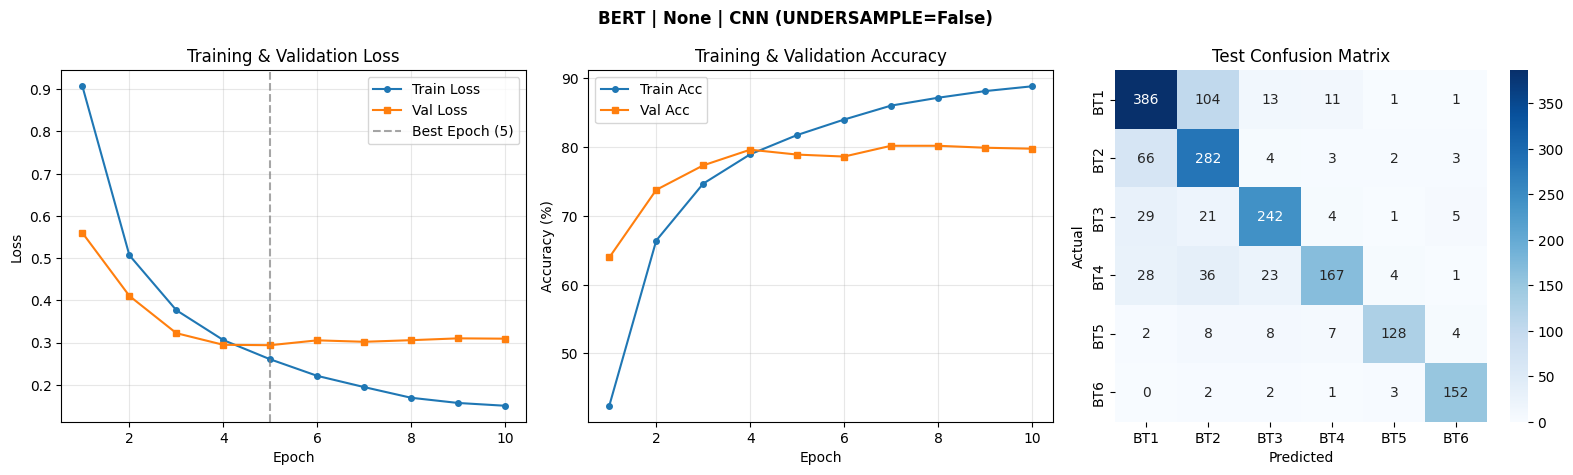


RUN: Embedding=BERT (bert-base-uncased) | Keywords=None (none) | Model=LSTM (lstm) | UNDERSAMPLE=False


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Trainable params: 15,785,350 / 110,501,254 | num_keywords=0
Epoch [01/50] Train Loss: 0.8695, Train Acc: 45.21% | Val Loss: 0.5373, Val Acc: 66.10%
Epoch [02/50] Train Loss: 0.5044, Train Acc: 65.55% | Val Loss: 0.3926, Val Acc: 72.93%
Epoch [03/50] Train Loss: 0.3846, Train Acc: 73.35% | Val Loss: 0.3351, Val Acc: 76.50%
Epoch [04/50] Train Loss: 0.3175, Train Acc: 77.37% | Val Loss: 0.2963, Val Acc: 78.63%
Epoch [05/50] Train Loss: 0.2751, Train Acc: 79.75% | Val Loss: 0.2880, Val Acc: 77.64%
Epoch [06/50] Train Loss: 0.2401, Train Acc: 82.02% | Val Loss: 0.2861, Val Acc: 79.34%
Epoch [07/50] Train Loss: 0.2151, Train Acc: 84.09% | Val Loss: 0.2830, Val Acc: 79.20%
Epoch [08/50] Train Loss: 0.1986, Train Acc: 85.01% | Val Loss: 0.2901, Val Acc: 78.21%
Epoch [09/50] Train Loss: 0.1856, Train Acc: 85.72% | Val Loss: 0.2902, Val Acc: 79.49%
Epoch [10/50] Train Loss: 0.1816, Train Acc: 85.98% | Val Loss: 0.2900, Val Acc: 79.49%
Epoch [11/50] Train Loss: 0.2085, Train Acc: 83.93% | Val Lo

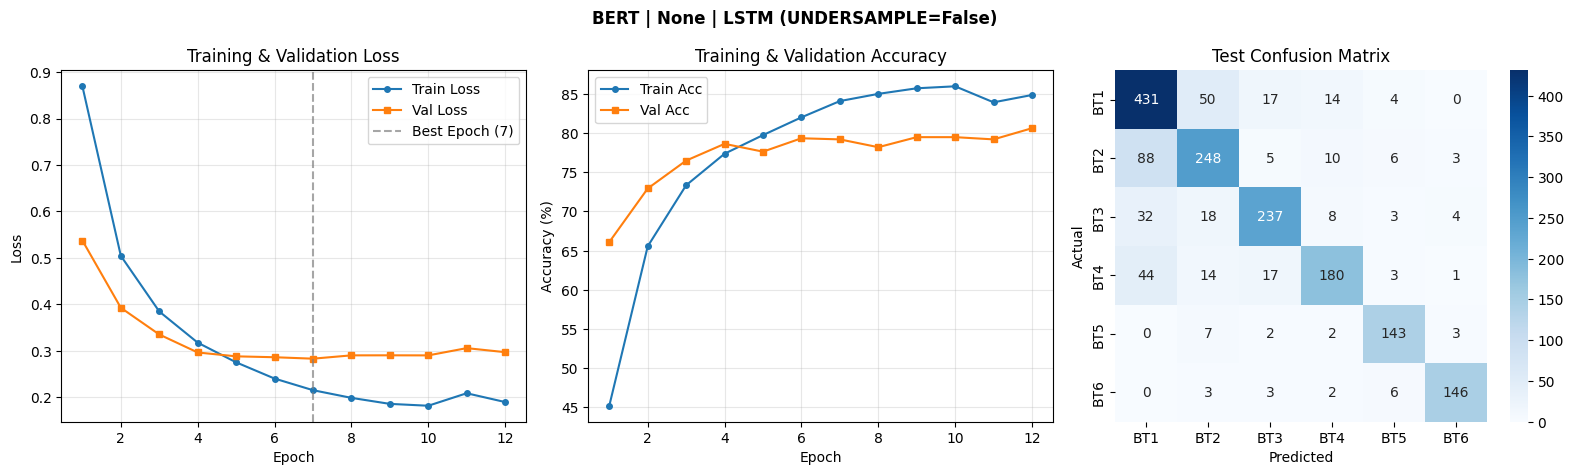


RUN: Embedding=BERT (bert-base-uncased) | Keywords=None (none) | Model=CNN-LSTM (cnn_lstm) | UNDERSAMPLE=False


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Trainable params: 16,121,414 / 110,837,318 | num_keywords=0
Epoch [01/50] Train Loss: 0.8651, Train Acc: 44.89% | Val Loss: 0.5170, Val Acc: 67.38%
Epoch [02/50] Train Loss: 0.4883, Train Acc: 66.85% | Val Loss: 0.3774, Val Acc: 73.79%
Epoch [03/50] Train Loss: 0.3642, Train Acc: 75.00% | Val Loss: 0.3271, Val Acc: 76.78%
Epoch [04/50] Train Loss: 0.2980, Train Acc: 79.08% | Val Loss: 0.2895, Val Acc: 79.91%
Epoch [05/50] Train Loss: 0.2623, Train Acc: 80.87% | Val Loss: 0.2927, Val Acc: 78.35%
Epoch [06/50] Train Loss: 0.2197, Train Acc: 83.41% | Val Loss: 0.2916, Val Acc: 79.34%
Epoch [07/50] Train Loss: 0.2016, Train Acc: 84.85% | Val Loss: 0.2860, Val Acc: 79.63%
Epoch [08/50] Train Loss: 0.1753, Train Acc: 86.26% | Val Loss: 0.2890, Val Acc: 80.06%
Epoch [09/50] Train Loss: 0.1693, Train Acc: 86.86% | Val Loss: 0.2886, Val Acc: 79.77%
Epoch [10/50] Train Loss: 0.1638, Train Acc: 87.13% | Val Loss: 0.2885, Val Acc: 80.48%
Epoch [11/50] Train Loss: 0.1940, Train Acc: 84.98% | Val Lo

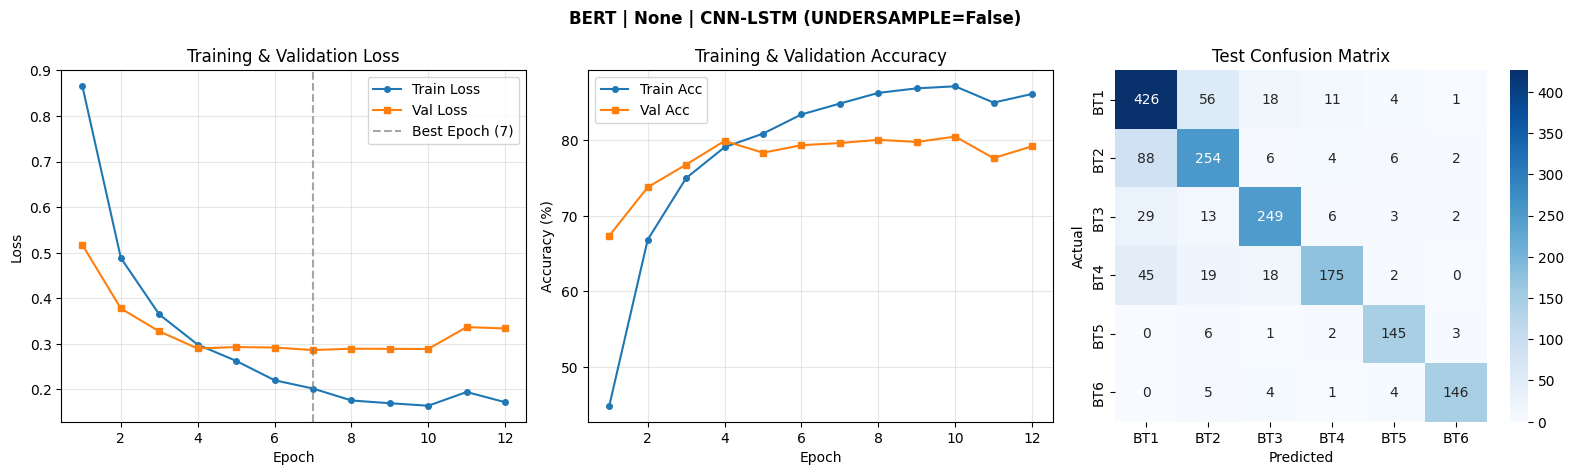


>>> Prepared keyword features for mode='tfidf': train=(6311, 90), val=(702, 90), test=(1754, 90)

RUN: Embedding=BERT (bert-base-uncased) | Keywords=TF-IDF (tfidf) | Model=CNN (cnn) | UNDERSAMPLE=False


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Trainable params: 15,158,534 / 109,874,438 | num_keywords=90
Epoch [01/50] Train Loss: 0.9368, Train Acc: 40.25% | Val Loss: 0.6056, Val Acc: 58.83%
Epoch [02/50] Train Loss: 0.5204, Train Acc: 65.62% | Val Loss: 0.4117, Val Acc: 74.50%
Epoch [03/50] Train Loss: 0.3875, Train Acc: 74.09% | Val Loss: 0.3492, Val Acc: 76.78%
Epoch [04/50] Train Loss: 0.3208, Train Acc: 77.37% | Val Loss: 0.3125, Val Acc: 78.21%
Epoch [05/50] Train Loss: 0.2729, Train Acc: 80.37% | Val Loss: 0.3104, Val Acc: 77.49%
Epoch [06/50] Train Loss: 0.2265, Train Acc: 83.36% | Val Loss: 0.3135, Val Acc: 78.35%
Epoch [07/50] Train Loss: 0.1996, Train Acc: 85.39% | Val Loss: 0.2938, Val Acc: 80.77%
Epoch [08/50] Train Loss: 0.1747, Train Acc: 86.12% | Val Loss: 0.3016, Val Acc: 79.49%
Epoch [09/50] Train Loss: 0.1643, Train Acc: 86.98% | Val Loss: 0.3004, Val Acc: 80.06%
Epoch [10/50] Train Loss: 0.1543, Train Acc: 88.13% | Val Loss: 0.3020, Val Acc: 79.77%
Epoch [11/50] Train Loss: 0.1956, Train Acc: 85.03% | Val L

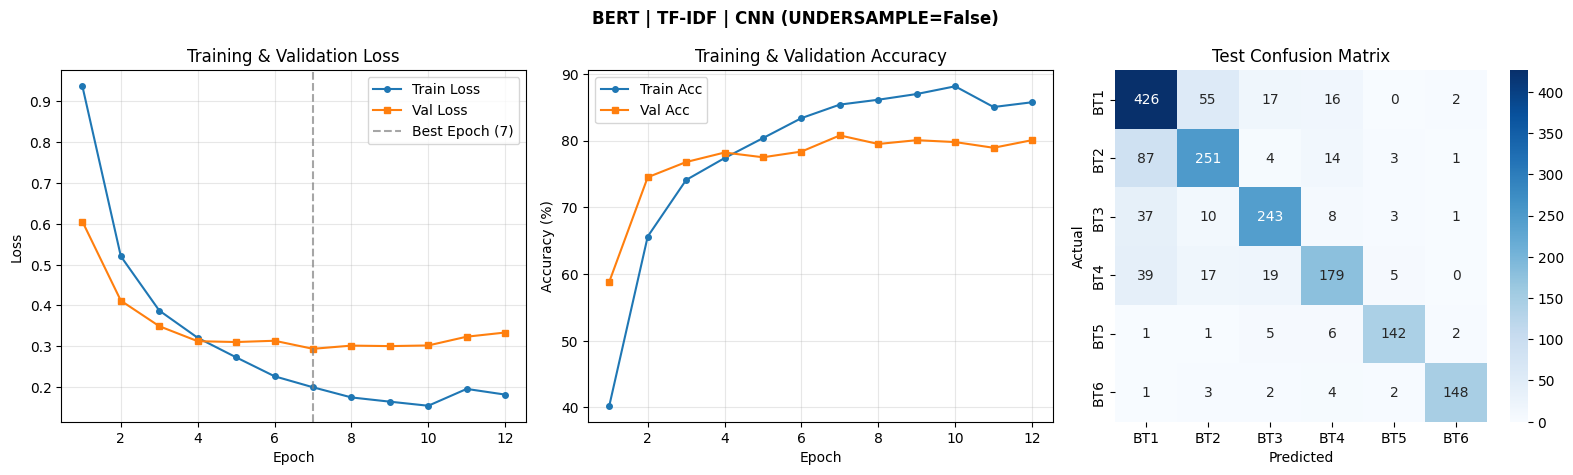


RUN: Embedding=BERT (bert-base-uncased) | Keywords=TF-IDF (tfidf) | Model=LSTM (lstm) | UNDERSAMPLE=False


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Trainable params: 15,807,558 / 110,523,462 | num_keywords=90
Epoch [01/50] Train Loss: 0.8564, Train Acc: 46.36% | Val Loss: 0.4856, Val Acc: 68.09%
Epoch [02/50] Train Loss: 0.4656, Train Acc: 68.21% | Val Loss: 0.3621, Val Acc: 74.79%
Epoch [03/50] Train Loss: 0.3655, Train Acc: 74.54% | Val Loss: 0.3306, Val Acc: 76.92%
Epoch [04/50] Train Loss: 0.3038, Train Acc: 78.64% | Val Loss: 0.2918, Val Acc: 79.91%
Epoch [05/50] Train Loss: 0.2661, Train Acc: 80.80% | Val Loss: 0.2868, Val Acc: 78.49%
Epoch [06/50] Train Loss: 0.2311, Train Acc: 82.89% | Val Loss: 0.2805, Val Acc: 79.49%
Epoch [07/50] Train Loss: 0.2113, Train Acc: 84.08% | Val Loss: 0.2731, Val Acc: 80.63%
Epoch [08/50] Train Loss: 0.1920, Train Acc: 85.68% | Val Loss: 0.2795, Val Acc: 80.77%
Epoch [09/50] Train Loss: 0.1800, Train Acc: 86.04% | Val Loss: 0.2771, Val Acc: 80.63%
Epoch [10/50] Train Loss: 0.1789, Train Acc: 85.80% | Val Loss: 0.2762, Val Acc: 80.63%
Epoch [11/50] Train Loss: 0.2022, Train Acc: 84.30% | Val L

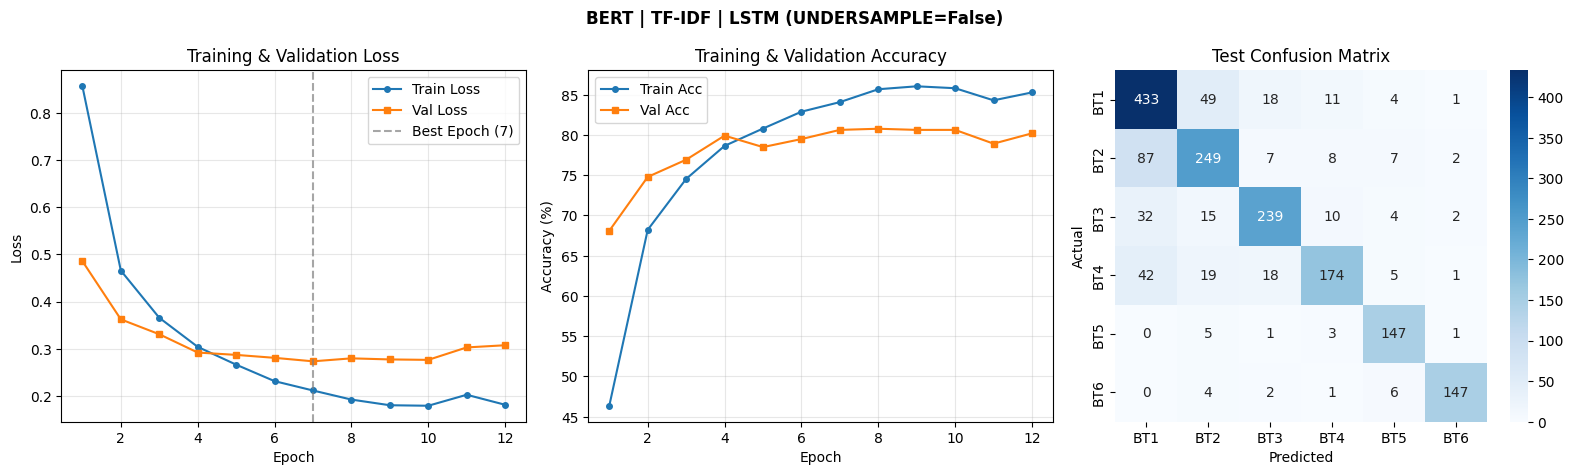


RUN: Embedding=BERT (bert-base-uncased) | Keywords=TF-IDF (tfidf) | Model=CNN-LSTM (cnn_lstm) | UNDERSAMPLE=False


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Trainable params: 16,143,622 / 110,859,526 | num_keywords=90
Epoch [01/50] Train Loss: 0.8461, Train Acc: 44.95% | Val Loss: 0.4974, Val Acc: 67.38%
Epoch [02/50] Train Loss: 0.4764, Train Acc: 67.60% | Val Loss: 0.3687, Val Acc: 75.36%
Epoch [03/50] Train Loss: 0.3639, Train Acc: 74.57% | Val Loss: 0.3338, Val Acc: 76.78%
Epoch [04/50] Train Loss: 0.3001, Train Acc: 78.61% | Val Loss: 0.3008, Val Acc: 78.06%
Epoch [05/50] Train Loss: 0.2568, Train Acc: 80.83% | Val Loss: 0.2894, Val Acc: 79.20%
Epoch [06/50] Train Loss: 0.2232, Train Acc: 83.30% | Val Loss: 0.2887, Val Acc: 79.49%
Epoch [07/50] Train Loss: 0.1991, Train Acc: 84.85% | Val Loss: 0.2815, Val Acc: 79.77%
Epoch [08/50] Train Loss: 0.1783, Train Acc: 86.10% | Val Loss: 0.2848, Val Acc: 79.63%
Epoch [09/50] Train Loss: 0.1637, Train Acc: 86.98% | Val Loss: 0.2895, Val Acc: 79.91%
Epoch [10/50] Train Loss: 0.1604, Train Acc: 87.29% | Val Loss: 0.2875, Val Acc: 80.63%
Epoch [11/50] Train Loss: 0.1912, Train Acc: 85.01% | Val L

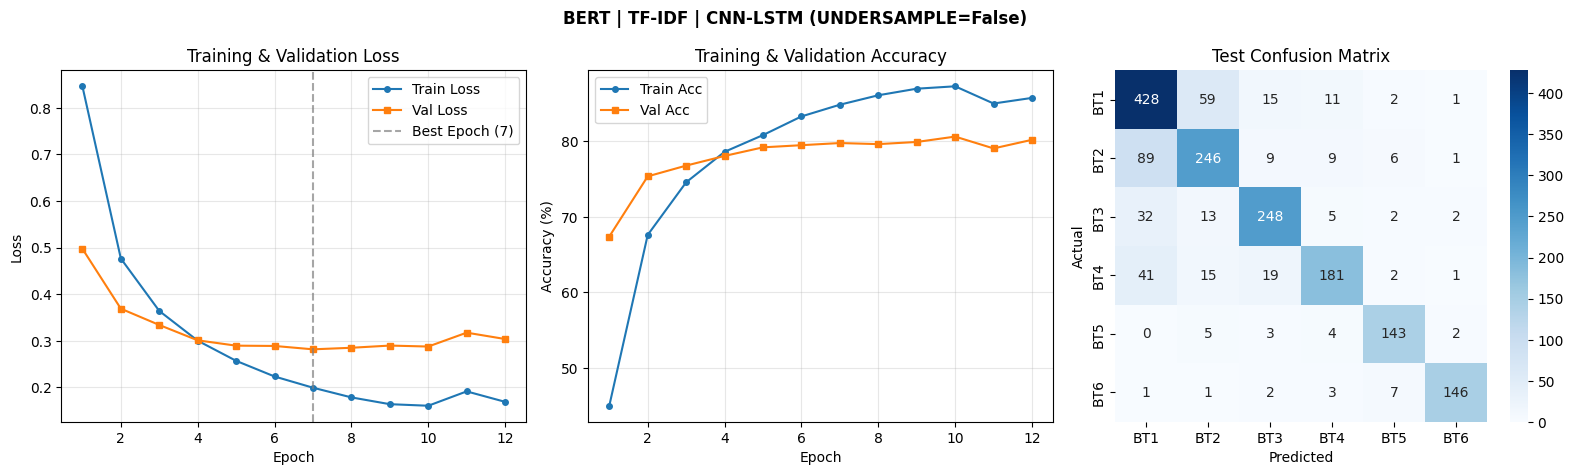


>>> Prepared keyword features for mode='tfidf_filter': train=(6311, 270), val=(702, 270), test=(1754, 270)

RUN: Embedding=BERT (bert-base-uncased) | Keywords=TF-IDF + Filtered Keyword (tfidf_filter) | Model=CNN (cnn) | UNDERSAMPLE=False


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Trainable params: 15,170,054 / 109,885,958 | num_keywords=270
Epoch [01/50] Train Loss: 0.9157, Train Acc: 41.20% | Val Loss: 0.5740, Val Acc: 60.54%
Epoch [02/50] Train Loss: 0.5074, Train Acc: 65.82% | Val Loss: 0.3920, Val Acc: 75.21%
Epoch [03/50] Train Loss: 0.3670, Train Acc: 74.89% | Val Loss: 0.3340, Val Acc: 76.07%
Epoch [04/50] Train Loss: 0.2956, Train Acc: 78.93% | Val Loss: 0.3040, Val Acc: 78.63%
Epoch [05/50] Train Loss: 0.2477, Train Acc: 82.05% | Val Loss: 0.3187, Val Acc: 77.21%
Epoch [06/50] Train Loss: 0.2164, Train Acc: 83.49% | Val Loss: 0.3166, Val Acc: 79.49%
Epoch [07/50] Train Loss: 0.1905, Train Acc: 85.50% | Val Loss: 0.3092, Val Acc: 78.92%
Epoch [08/50] Train Loss: 0.1635, Train Acc: 87.28% | Val Loss: 0.3168, Val Acc: 80.63%
Epoch [09/50] Train Loss: 0.1493, Train Acc: 88.48% | Val Loss: 0.3147, Val Acc: 80.34%
Early stopping triggered at epoch 9 (best epoch: 4)

Test Results -> Accuracy: 0.7782 | Precision (w): 0.7797 | Recall (w): 0.7782 | F1 (w): 0.777

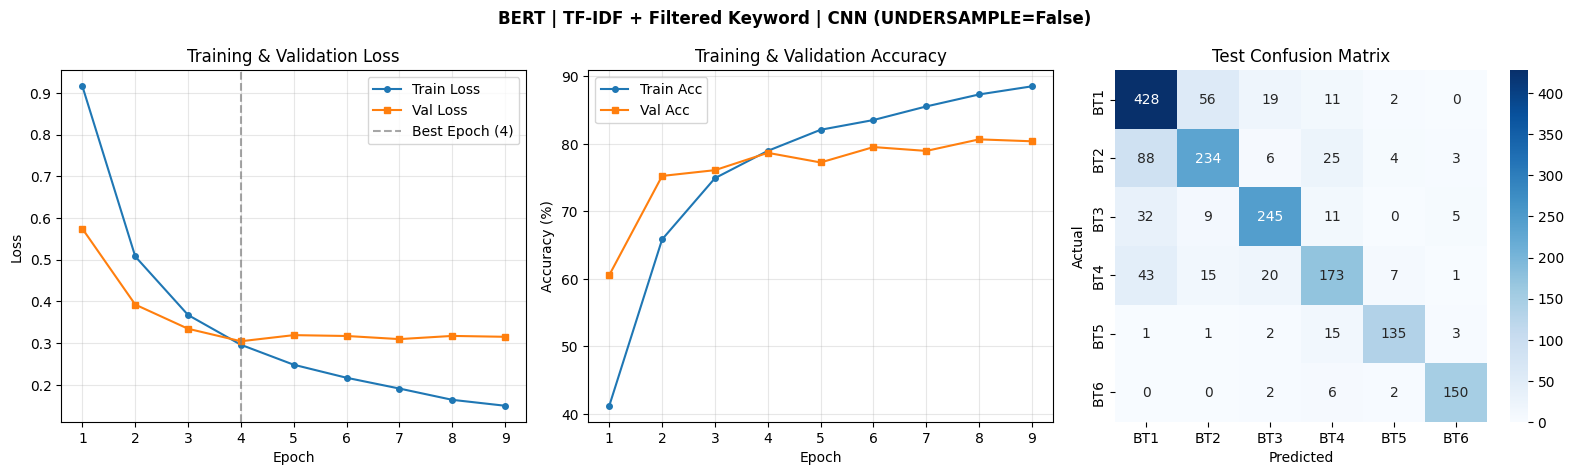


RUN: Embedding=BERT (bert-base-uncased) | Keywords=TF-IDF + Filtered Keyword (tfidf_filter) | Model=LSTM (lstm) | UNDERSAMPLE=False


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Trainable params: 15,819,078 / 110,534,982 | num_keywords=270
Epoch [01/50] Train Loss: 0.8652, Train Acc: 44.95% | Val Loss: 0.5185, Val Acc: 66.38%
Epoch [02/50] Train Loss: 0.4873, Train Acc: 66.80% | Val Loss: 0.3798, Val Acc: 74.64%
Epoch [03/50] Train Loss: 0.3682, Train Acc: 74.50% | Val Loss: 0.3363, Val Acc: 76.21%
Epoch [04/50] Train Loss: 0.3061, Train Acc: 78.13% | Val Loss: 0.3033, Val Acc: 78.35%
Epoch [05/50] Train Loss: 0.2667, Train Acc: 80.97% | Val Loss: 0.3007, Val Acc: 77.78%
Epoch [06/50] Train Loss: 0.2306, Train Acc: 82.82% | Val Loss: 0.2881, Val Acc: 79.20%
Epoch [07/50] Train Loss: 0.2086, Train Acc: 84.49% | Val Loss: 0.2833, Val Acc: 79.91%
Epoch [08/50] Train Loss: 0.1898, Train Acc: 85.33% | Val Loss: 0.2866, Val Acc: 79.91%
Epoch [09/50] Train Loss: 0.1825, Train Acc: 85.99% | Val Loss: 0.2906, Val Acc: 80.77%
Epoch [10/50] Train Loss: 0.1757, Train Acc: 86.77% | Val Loss: 0.2881, Val Acc: 81.34%
Epoch [11/50] Train Loss: 0.2025, Train Acc: 84.47% | Val 

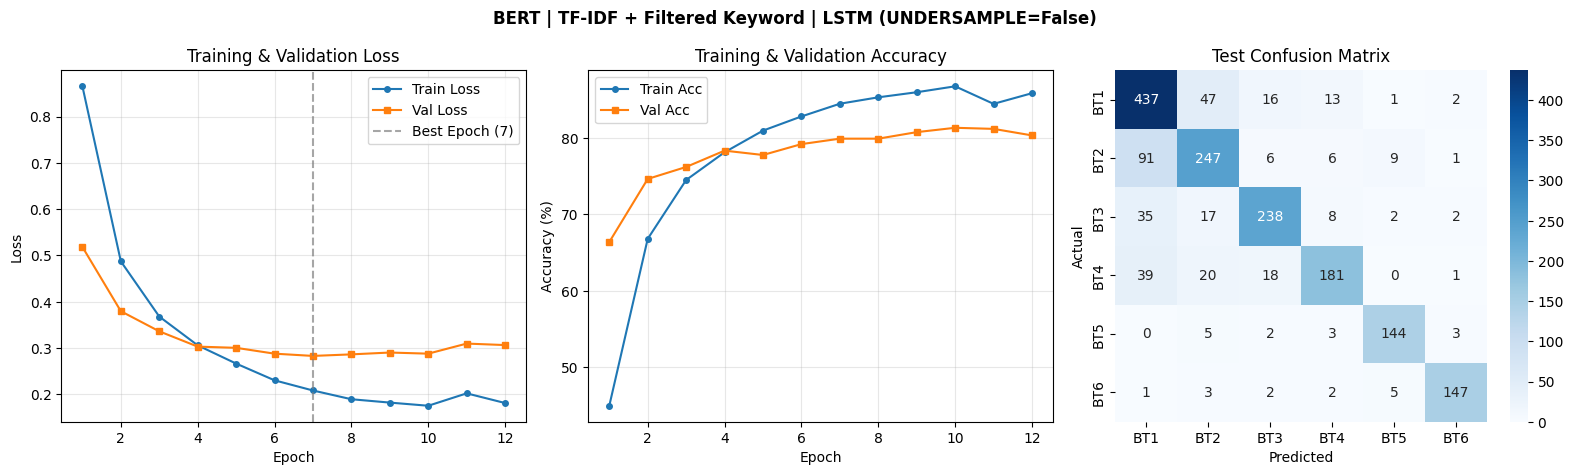


RUN: Embedding=BERT (bert-base-uncased) | Keywords=TF-IDF + Filtered Keyword (tfidf_filter) | Model=CNN-LSTM (cnn_lstm) | UNDERSAMPLE=False


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Trainable params: 16,155,142 / 110,871,046 | num_keywords=270
Epoch [01/50] Train Loss: 0.8662, Train Acc: 42.37% | Val Loss: 0.5377, Val Acc: 61.40%
Epoch [02/50] Train Loss: 0.5008, Train Acc: 65.05% | Val Loss: 0.3836, Val Acc: 74.36%
Epoch [03/50] Train Loss: 0.3740, Train Acc: 73.76% | Val Loss: 0.3252, Val Acc: 77.92%
Epoch [04/50] Train Loss: 0.3032, Train Acc: 78.42% | Val Loss: 0.2933, Val Acc: 79.34%
Epoch [05/50] Train Loss: 0.2544, Train Acc: 81.27% | Val Loss: 0.2809, Val Acc: 79.06%
Epoch [06/50] Train Loss: 0.2186, Train Acc: 83.28% | Val Loss: 0.2741, Val Acc: 80.91%
Epoch [07/50] Train Loss: 0.1920, Train Acc: 85.15% | Val Loss: 0.2767, Val Acc: 80.91%
Epoch [08/50] Train Loss: 0.1678, Train Acc: 86.74% | Val Loss: 0.2781, Val Acc: 80.48%
Epoch [09/50] Train Loss: 0.1573, Train Acc: 87.55% | Val Loss: 0.2848, Val Acc: 80.34%
Epoch [10/50] Train Loss: 0.1525, Train Acc: 88.05% | Val Loss: 0.2832, Val Acc: 80.91%
Epoch [11/50] Train Loss: 0.1829, Train Acc: 85.50% | Val 

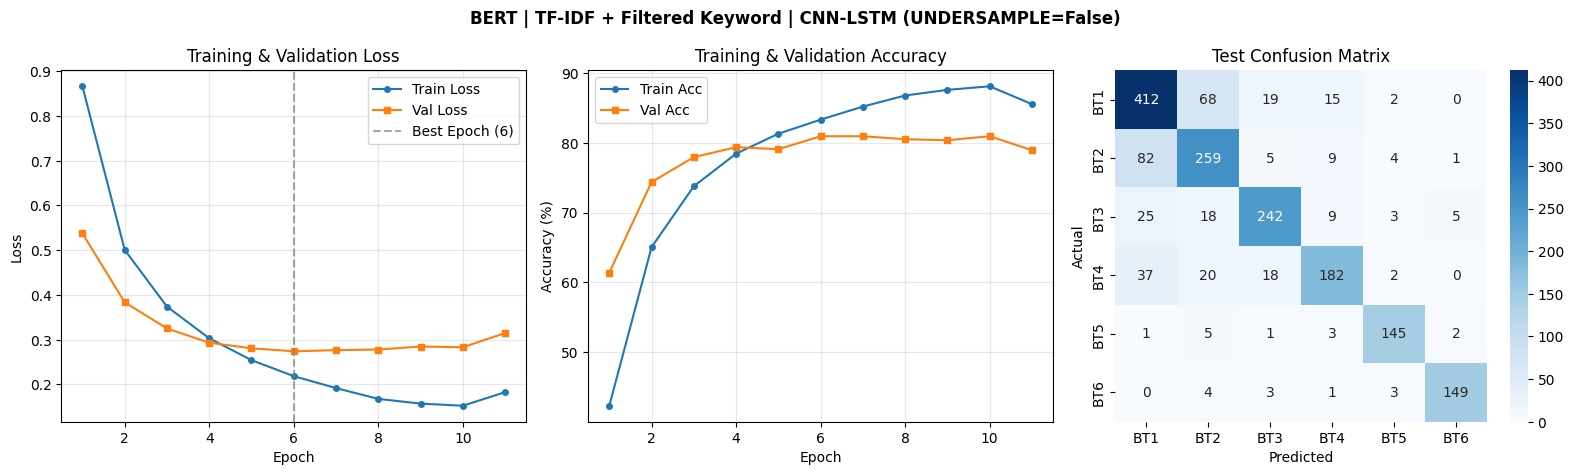

In [6]:
EMBEDDING_NAME = "bert-base-uncased"
KEYWORD_MODES = ["none", "tfidf", "tfidf_filter"]
VARIANTS = ["cnn", "lstm", "cnn_lstm"]

all_runs = {}
for keyword_mode in KEYWORD_MODES:
    X_kw_train, X_kw_val, X_kw_test = prepare_keyword_features(
        train_df, val_df, test_df, keyword_mode=keyword_mode, filtered_vocab=K
    )
    print(
        f"\n>>> Prepared keyword features for mode='{keyword_mode}': "
        f"train={X_kw_train.shape}, val={X_kw_val.shape}, test={X_kw_test.shape}"
    )
    for variant in VARIANTS:
        run_out = run_single_experiment(
            embedding_name=EMBEDDING_NAME,
            variant=variant,
            keyword_mode=keyword_mode,
            train_df=train_df,
            val_df=val_df,
            test_df=test_df,
            classes=classes,
            X_kw_train=X_kw_train,
            X_kw_val=X_kw_val,
            X_kw_test=X_kw_test,
            epochs=50,
            patience=5,
            batch_size=16,
            seed=SEED,
        )
        all_runs[(EMBEDDING_NAME, variant, keyword_mode)] = run_out

# 6. BERT Summary Table (Table 4)

In [7]:
table_num = "Table 5" if UNDERSAMPLE else "Table 4"
summary_rows = []
for (emb, var, kw), out in all_runs.items():
    r = out["result"]
    summary_rows.append({
        "Embedding Model": EMBEDDING_LABEL_MAP.get(emb, emb),
        "Keyword Features": KEYWORD_LABEL_MAP.get(kw, kw),
        "Model": VARIANT_LABEL_MAP.get(var, var),
        "Best Epoch": r["best_epoch"],
        "Accuracy": r["accuracy"],
        "Precision": r["precision_w"],
        "Recall": r["recall_w"],
        "F1": r["f1_weighted"],
        "F1_Macro": r["f1_macro"],
        "Adj_Errors": r["adjacent_errors"],
        "NonAdj_Errors": r["non_adjacent_errors"],
        "Total_Misclassified": r["total_misclassified"],
    })

summary_df = pd.DataFrame(summary_rows)

print(f"=== {table_num} Summary (bert, UNDERSAMPLE={UNDERSAMPLE}) - 3 Decimals ===")
summary_3dec = summary_df.copy()
for col in ["Accuracy", "Precision", "Recall", "F1", "F1_Macro"]:
    summary_3dec[col] = summary_3dec[col].map(lambda x: f"{x:.3f}")
display(summary_3dec)

print(f"\n=== {table_num} Summary (bert, UNDERSAMPLE={UNDERSAMPLE}) - 4 Decimals ===")
summary_4dec = summary_df.copy()
for col in ["Accuracy", "Precision", "Recall", "F1", "F1_Macro"]:
    summary_4dec[col] = summary_4dec[col].map(lambda x: f"{x:.4f}")
display(summary_4dec)

os.makedirs("outputs", exist_ok=True)
summary_df.to_csv(f"outputs/summary_bert_undersample{UNDERSAMPLE}.csv", index=False)
with open(f"outputs/summary_bert_undersample{UNDERSAMPLE}.json", "w") as f:
    json.dump(summary_rows, f, indent=2)

=== Table 4 Summary (bert, UNDERSAMPLE=False) - 3 Decimals ===


,Embedding Model,Keyword Features,Model,Best Epoch,Accuracy,Precision,Recall,F1,F1_Macro,Adj_Errors,NonAdj_Errors,Total_Misclassified
0,BERT,None,CNN,5,0.774,0.786,0.774,0.775,0.799,240,157,397
1,BERT,None,LSTM,7,0.790,0.793,0.790,0.789,0.811,200,169,369
2,BERT,None,CNN-LSTM,7,0.795,0.801,0.795,0.795,0.819,198,161,359
3,BERT,TF-IDF,CNN,7,0.792,0.795,0.792,0.792,0.817,198,167,365
4,BERT,TF-IDF,LSTM,7,0.792,0.796,0.792,0.791,0.813,201,164,365
5,BERT,TF-IDF,CNN-LSTM,7,0.794,0.798,0.794,0.793,0.817,209,153,362
6,BERT,TF-IDF + Filtered Keyword,CNN,4,0.778,0.780,0.778,0.777,0.799,217,172,389
7,BERT,TF-IDF + Filtered Keyword,LSTM,7,0.795,0.800,0.795,0.794,0.818,198,162,360
8,BERT,TF-IDF + Filtered Keyword,CNN-LSTM,6,0.792,0.795,0.792,0.792,0.819,210,155,365



=== Table 4 Summary (bert, UNDERSAMPLE=False) - 4 Decimals ===


,Embedding Model,Keyword Features,Model,Best Epoch,Accuracy,Precision,Recall,F1,F1_Macro,Adj_Errors,NonAdj_Errors,Total_Misclassified
0,BERT,None,CNN,5,0.7737,0.7864,0.7737,0.7754,0.7994,240,157,397
1,BERT,None,LSTM,7,0.7896,0.7935,0.7896,0.7891,0.8108,200,169,369
2,BERT,None,CNN-LSTM,7,0.7953,0.8011,0.7953,0.7952,0.8191,198,161,359
3,BERT,TF-IDF,CNN,7,0.7919,0.7953,0.7919,0.7918,0.8167,198,167,365
4,BERT,TF-IDF,LSTM,7,0.7919,0.7960,0.7919,0.7910,0.8131,201,164,365
5,BERT,TF-IDF,CNN-LSTM,7,0.7936,0.7978,0.7936,0.7934,0.8172,209,153,362
6,BERT,TF-IDF + Filtered Keyword,CNN,4,0.7782,0.7797,0.7782,0.7770,0.7985,217,172,389
7,BERT,TF-IDF + Filtered Keyword,LSTM,7,0.7948,0.7996,0.7948,0.7943,0.8176,198,162,360
8,BERT,TF-IDF + Filtered Keyword,CNN-LSTM,6,0.7919,0.7953,0.7919,0.7924,0.8189,210,155,365


# 7. Per-Class & Confusion Analysis (Table 6a, Table 6b & Fig. 2)


Table 6a & 6b: BERT-CNN (Baseline 'none' vs Hybrid 'tfidf_filter', UNDERSAMPLE=False)

Table 6a. Per-class Precision, Recall, and F1-score:


,Level,Support,Base P,Base R,Base F1,Hybrid P,Hybrid R,Hybrid F1,Delta_F1
0,BT1,516,0.755,0.748,0.752,0.723,0.829,0.773,+0.021
1,BT2,360,0.623,0.783,0.694,0.743,0.650,0.693,-0.000
2,BT3,302,0.829,0.801,0.815,0.833,0.811,0.822,+0.007
3,BT4,259,0.865,0.645,0.739,0.718,0.668,0.692,-0.047
4,BT5,157,0.921,0.815,0.865,0.900,0.860,0.879,+0.015
5,BT6,160,0.916,0.950,0.933,0.926,0.938,0.932,-0.001
6,Macro avg,1754,0.818,0.790,0.799,0.807,0.793,0.799,-0.001
7,Weighted avg,1754,0.786,0.774,0.775,0.780,0.778,0.777,+0.002



Table 6b. Confusions Between Level Pairs:


,Confusion Pair,Baseline,Hybrid,Change
0,BT1 <-> BT2,170,144,-26
1,BT2 <-> BT3,25,15,-10
2,BT3 <-> BT4,27,31,+4
3,BT4 <-> BT5,11,22,+11
4,BT5 <-> BT6,7,5,-2
5,All adjacent pairs,240 (60.5%),217 (55.8%),-23
6,BT1 -> BT4 (actual -> predicted),11,11,+0
7,BT4 -> BT1 (actual -> predicted),28,43,+15
8,BT1 <-> BT4 (non-adjacent),39,54,+15
9,All non-adjacent pairs,157 (39.5%),172 (44.2%),+15


Top non-adjacent pairs (Baseline): [('BT4->BT2', 36), ('BT3->BT1', 29), ('BT4->BT1', 28), ('BT1->BT3', 13), ('BT1->BT4', 11)]
Top non-adjacent pairs (Hybrid):   [('BT4->BT1', 43), ('BT3->BT1', 32), ('BT2->BT4', 25), ('BT1->BT3', 19), ('BT4->BT2', 15)]

Table 6a & 6b: BERT-LSTM (Baseline 'none' vs Hybrid 'tfidf_filter', UNDERSAMPLE=False)

Table 6a. Per-class Precision, Recall, and F1-score:


,Level,Support,Base P,Base R,Base F1,Hybrid P,Hybrid R,Hybrid F1,Delta_F1
0,BT1,516,0.724,0.835,0.776,0.725,0.847,0.781,+0.005
1,BT2,360,0.729,0.689,0.709,0.729,0.686,0.707,-0.002
2,BT3,302,0.843,0.785,0.813,0.844,0.788,0.815,+0.002
3,BT4,259,0.833,0.695,0.758,0.850,0.699,0.767,+0.009
4,BT5,157,0.867,0.911,0.888,0.894,0.917,0.906,+0.017
5,BT6,160,0.930,0.912,0.921,0.942,0.919,0.930,+0.009
6,Macro avg,1754,0.821,0.805,0.811,0.831,0.809,0.818,+0.007
7,Weighted avg,1754,0.793,0.790,0.789,0.800,0.795,0.794,+0.005


... (3 outputs left out)

,Level,Support,Base P,Base R,Base F1,Hybrid P,Hybrid R,Hybrid F1,Delta_F1
0,BT1,516,0.724,0.826,0.772,0.740,0.798,0.768,-0.004
1,BT2,360,0.720,0.706,0.712,0.693,0.719,0.706,-0.007
2,BT3,302,0.841,0.825,0.833,0.840,0.801,0.820,-0.012
3,BT4,259,0.879,0.676,0.764,0.831,0.703,0.762,-0.003
4,BT5,157,0.884,0.924,0.903,0.912,0.924,0.918,+0.014
5,BT6,160,0.948,0.912,0.930,0.949,0.931,0.940,+0.010
6,Macro avg,1754,0.833,0.811,0.819,0.827,0.813,0.819,-0.000
7,Weighted avg,1754,0.801,0.795,0.795,0.795,0.792,0.792,-0.003



Table 6b. Confusions Between Level Pairs:


,Confusion Pair,Baseline,Hybrid,Change
0,BT1 <-> BT2,144,150,+6
1,BT2 <-> BT3,19,23,+4
2,BT3 <-> BT4,24,27,+3
3,BT4 <-> BT5,4,5,+1
4,BT5 <-> BT6,7,5,-2
5,All adjacent pairs,198 (55.2%),210 (57.5%),+12
6,BT1 -> BT4 (actual -> predicted),11,15,+4
7,BT4 -> BT1 (actual -> predicted),45,37,-8
8,BT1 <-> BT4 (non-adjacent),56,52,-4
9,All non-adjacent pairs,161 (44.8%),155 (42.5%),-6


Top non-adjacent pairs (Baseline): [('BT4->BT1', 45), ('BT3->BT1', 29), ('BT4->BT2', 19), ('BT1->BT3', 18), ('BT1->BT4', 11)]
Top non-adjacent pairs (Hybrid):   [('BT4->BT1', 37), ('BT3->BT1', 25), ('BT4->BT2', 20), ('BT1->BT3', 19), ('BT1->BT4', 15)]


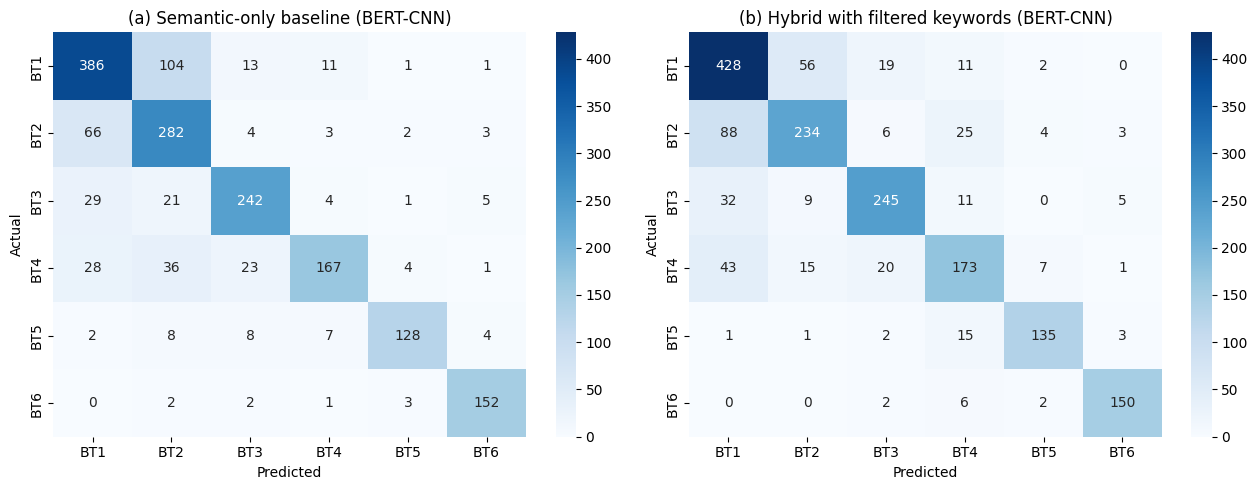

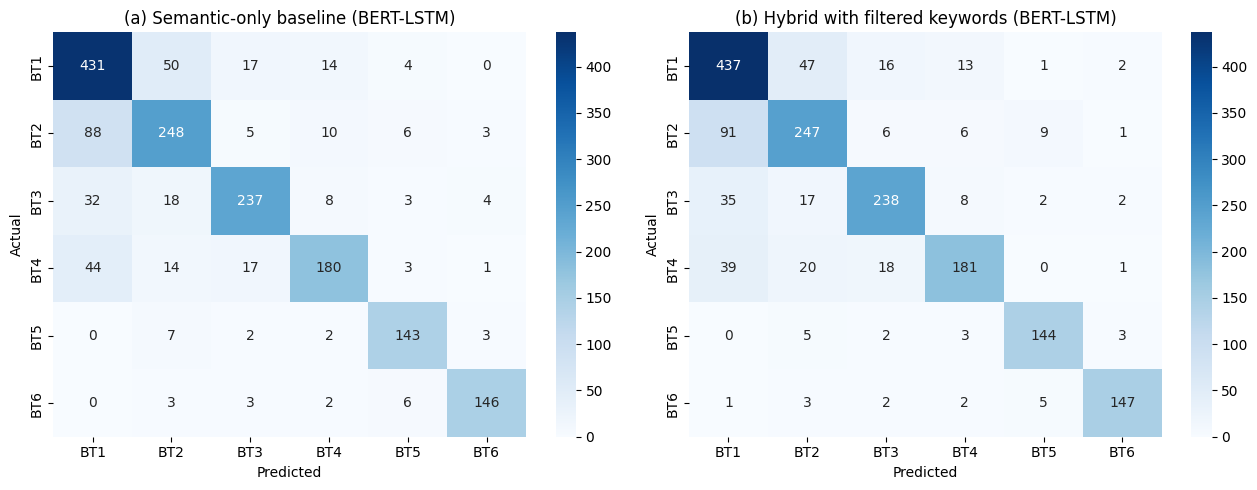

In [8]:
def build_table6a(base_rep: dict, hybrid_rep: dict, classes: list) -> pd.DataFrame:
    rows = []
    for lvl in classes:
        bp, br, bf = base_rep[lvl]["precision"], base_rep[lvl]["recall"], base_rep[lvl]["f1-score"]
        hp, hr, hf = hybrid_rep[lvl]["precision"], hybrid_rep[lvl]["recall"], hybrid_rep[lvl]["f1-score"]
        sup = int(base_rep[lvl]["support"])
        rows.append({
            "Level": lvl,
            "Support": sup,
            "Base P": f"{bp:.3f}",
            "Base R": f"{br:.3f}",
            "Base F1": f"{bf:.3f}",
            "Hybrid P": f"{hp:.3f}",
            "Hybrid R": f"{hr:.3f}",
            "Hybrid F1": f"{hf:.3f}",
            "Delta_F1": f"{hf - bf:+.3f}",
        })
    for key, label in [("macro avg", "Macro avg"), ("weighted avg", "Weighted avg")]:
        bp, br, bf = base_rep[key]["precision"], base_rep[key]["recall"], base_rep[key]["f1-score"]
        hp, hr, hf = hybrid_rep[key]["precision"], hybrid_rep[key]["recall"], hybrid_rep[key]["f1-score"]
        sup = int(base_rep[key]["support"])
        rows.append({
            "Level": label,
            "Support": sup,
            "Base P": f"{bp:.3f}",
            "Base R": f"{br:.3f}",
            "Base F1": f"{bf:.3f}",
            "Hybrid P": f"{hp:.3f}",
            "Hybrid R": f"{hr:.3f}",
            "Hybrid F1": f"{hf:.3f}",
            "Delta_F1": f"{hf - bf:+.3f}",
        })
    return pd.DataFrame(rows)


def build_table6b(base_cm: np.ndarray, hybrid_cm: np.ndarray, classes: list) -> pd.DataFrame:
    base_adj, base_adj_tot, base_nonadj_tot, base_tot, _ = compute_confusion_stats(base_cm, classes)
    hyb_adj, hyb_adj_tot, hyb_nonadj_tot, hyb_tot, _ = compute_confusion_stats(hybrid_cm, classes)

    rows = []
    for i in range(len(classes) - 1):
        key = f"{classes[i]}<->{classes[i + 1]}"
        b_val, h_val = base_adj[key], hyb_adj[key]
        rows.append({
            "Confusion Pair": f"{classes[i]} <-> {classes[i + 1]}",
            "Baseline": str(b_val),
            "Hybrid": str(h_val),
            "Change": f"{h_val - b_val:+d}",
        })

    rows.append({
        "Confusion Pair": "All adjacent pairs",
        "Baseline": f"{base_adj_tot} ({base_adj_tot / base_tot * 100:.1f}%)" if base_tot else "0",
        "Hybrid": f"{hyb_adj_tot} ({hyb_adj_tot / hyb_tot * 100:.1f}%)" if hyb_tot else "0",
        "Change": f"{hyb_adj_tot - base_adj_tot:+d}",
    })

    idx = {c: k for k, c in enumerate(classes)}
    if "BT1" in idx and "BT4" in idx:
        i1, i4 = idx["BT1"], idx["BT4"]
        b_14, h_14 = int(base_cm[i1, i4]), int(hybrid_cm[i1, i4])
        b_41, h_41 = int(base_cm[i4, i1]), int(hybrid_cm[i4, i1])
        rows.extend([
            {"Confusion Pair": "BT1 -> BT4 (actual -> predicted)", "Baseline": str(b_14), "Hybrid": str(h_14), "Change": f"{h_14 - b_14:+d}"},
            {"Confusion Pair": "BT4 -> BT1 (actual -> predicted)", "Baseline": str(b_41), "Hybrid": str(h_41), "Change": f"{h_41 - b_41:+d}"},
            {"Confusion Pair": "BT1 <-> BT4 (non-adjacent)", "Baseline": str(b_14 + b_41), "Hybrid": str(h_14 + h_41), "Change": f"{(h_14 + h_41) - (b_14 + b_41):+d}"},
        ])

    rows.append({
        "Confusion Pair": "All non-adjacent pairs",
        "Baseline": f"{base_nonadj_tot} ({base_nonadj_tot / base_tot * 100:.1f}%)" if base_tot else "0",
        "Hybrid": f"{hyb_nonadj_tot} ({hyb_nonadj_tot / hyb_tot * 100:.1f}%)" if hyb_tot else "0",
        "Change": f"{hyb_nonadj_tot - base_nonadj_tot:+d}",
    })
    rows.append({
        "Confusion Pair": "All misclassified questions",
        "Baseline": str(base_tot),
        "Hybrid": str(hyb_tot),
        "Change": f"{hyb_tot - base_tot:+d}",
    })
    return pd.DataFrame(rows)


table6_bundle = {}
for variant in VARIANTS:
    base_out = all_runs[(EMBEDDING_NAME, variant, "none")]
    hybrid_out = all_runs[(EMBEDDING_NAME, variant, "tfidf_filter")]

    df_6a = build_table6a(base_out["per_class"], hybrid_out["per_class"], classes)
    df_6b = build_table6b(base_out["cm"], hybrid_out["cm"], classes)

    print("\n" + "=" * 80)
    print(f"Table 6a & 6b: {EMBEDDING_LABEL_MAP.get(EMBEDDING_NAME)}-{VARIANT_LABEL_MAP.get(variant)} (Baseline 'none' vs Hybrid 'tfidf_filter', UNDERSAMPLE={UNDERSAMPLE})")
    print("=" * 80)
    print("\nTable 6a. Per-class Precision, Recall, and F1-score:")
    display(df_6a)

    print("\nTable 6b. Confusions Between Level Pairs:")
    display(df_6b)

    base_non_adj_top = sorted(
        base_out["result"]["non_adjacent_pairs"].items(), key=lambda kv: kv[1], reverse=True
    )[:5]
    hyb_non_adj_top = sorted(
        hybrid_out["result"]["non_adjacent_pairs"].items(), key=lambda kv: kv[1], reverse=True
    )[:5]
    print("Top non-adjacent pairs (Baseline):", base_non_adj_top)
    print("Top non-adjacent pairs (Hybrid):  ", hyb_non_adj_top)

    df_6a.to_csv(f"outputs/table6a_{EMBEDDING_NAME}_{variant}_undersample{UNDERSAMPLE}.csv", index=False)
    df_6b.to_csv(f"outputs/table6b_{EMBEDDING_NAME}_{variant}_undersample{UNDERSAMPLE}.csv", index=False)
    table6_bundle[variant] = {
        "table6a": df_6a.to_dict(orient="records"),
        "table6b": df_6b.to_dict(orient="records"),
    }

with open(f"outputs/table6_{EMBEDDING_NAME}_undersample{UNDERSAMPLE}.json", "w") as f:
    json.dump(table6_bundle, f, indent=2)

# Side-by-side Confusion Matrices (Fig. 2 style) for CNN and for the best tfidf_filter variant
best_hybrid_variant = max(
    VARIANTS,
    key=lambda v: all_runs[(EMBEDDING_NAME, v, "tfidf_filter")]["result"]["f1_weighted"],
)
plot_variants = ["cnn"] if best_hybrid_variant == "cnn" else ["cnn", best_hybrid_variant]

for pv in plot_variants:
    base_cm = all_runs[(EMBEDDING_NAME, pv, "none")]["cm"]
    hyb_cm = all_runs[(EMBEDDING_NAME, pv, "tfidf_filter")]["cm"]
    vmax = int(max(base_cm.max(), hyb_cm.max()))

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    sns.heatmap(
        base_cm, annot=True, fmt="d", cmap="Blues", vmin=0, vmax=vmax,
        xticklabels=classes, yticklabels=classes, ax=axes[0]
    )
    axes[0].set_title(f"(a) Semantic-only baseline ({EMBEDDING_LABEL_MAP.get(EMBEDDING_NAME)}-{VARIANT_LABEL_MAP.get(pv)})")
    axes[0].set_xlabel("Predicted")
    axes[0].set_ylabel("Actual")

    sns.heatmap(
        hyb_cm, annot=True, fmt="d", cmap="Blues", vmin=0, vmax=vmax,
        xticklabels=classes, yticklabels=classes, ax=axes[1]
    )
    axes[1].set_title(f"(b) Hybrid with filtered keywords ({EMBEDDING_LABEL_MAP.get(EMBEDDING_NAME)}-{VARIANT_LABEL_MAP.get(pv)})")
    axes[1].set_xlabel("Predicted")
    axes[1].set_ylabel("Actual")

    plt.tight_layout()
    plt.savefig(
        f"outputs/fig2_confusion_comparison_{EMBEDDING_NAME}_{pv}_undersample{UNDERSAMPLE}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

# 8. Package Lightweight Outputs

In [9]:
light_dir = f"outputs/_lightweight_bert_undersample{UNDERSAMPLE}"
if os.path.exists(light_dir):
    shutil.rmtree(light_dir)
os.makedirs(light_dir, exist_ok=True)

for root_dir, _, files in os.walk("outputs"):
    if "_lightweight_" in root_dir:
        continue
    for fname in files:
        if not fname.endswith(".pth"):
            src = os.path.join(root_dir, fname)
            rel = os.path.relpath(src, "outputs")
            dst = os.path.join(light_dir, rel)
            os.makedirs(os.path.dirname(dst), exist_ok=True)
            shutil.copy2(src, dst)

zip_name = f"results_bundle_bert_undersample{UNDERSAMPLE}"
shutil.make_archive(zip_name, "zip", light_dir)
shutil.rmtree(light_dir)
print(f"Created lightweight archive (all JSONs, CSVs, TXT reports, PNGs): {zip_name}.zip")

Created lightweight archive (all JSONs, CSVs, TXT reports, PNGs): results_bundle_bert_undersampleFalse.zip
